# Examination of Equivariance Properties of VGG Feature Maps

## 0. Setup 

In [44]:
import glob
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from PIL import Image, ImageDraw
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge, RidgeCV, orthogonal_mp_gram
from sklearn.metrics import r2_score, roc_auc_score
from sklearn.model_selection import train_test_split
from torchvision import models
from torchvision.transforms import functional as TF
from tqdm import tqdm

RANDOM_STATE = 42
IMG_SIZE = 32
BACKGROUND_GRAY = 0.5
BATCH_SIZE = 64
DATA_ROOT = Path("../dataset/coco_crops_transparent_8cat")

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(f"Using device: {device}")

IMAGENET_MEAN = models.VGG16_Weights.IMAGENET1K_V1.transforms().mean
IMAGENET_STD = models.VGG16_Weights.IMAGENET1K_V1.transforms().std


class PlainVGGFeatureExtractor(nn.Module):
    """VGG-16 features through layer 30 (inclusive) - 1x1x512 output at 32x32 input."""

    def __init__(self):
        super().__init__()
        weights = models.VGG16_Weights.IMAGENET1K_V1
        vgg = models.vgg16(weights=weights)
        self.features = nn.Sequential(*list(vgg.features.children())[:31])
        for p in self.parameters():
            p.requires_grad = False
        self.eval()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.features(x)


feature_extractor = PlainVGGFeatureExtractor().to(device)
print(feature_extractor)

Using device: mps
PlainVGGFeatureExtractor(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(kernel_

## 1. Feature Extraction Pipeline

For every image in `coco_crops_transparent_8cat` (all 16 category folders), we extract a 512-dim feature vector from VGG-16 layer 30. To make every rotation angle - including 0deg - directly comparable, all conditions go through the exact same resampling path, in this order:

1. Rotate the RGBA image at its original resolution with `resample=BILINEAR, expand=False`. This is applied even at `angle=0` so that every condition, including the "original" one, carries identical interpolation behavior.
2. Composite the rotated image onto a solid mid-gray background (`BACKGROUND_GRAY = 0.5`).
3. Apply a circular aperture: mask everything outside the image's inscribed circle to the same gray background. This is done after rotation and before resizing, so no angle gets extra or missing corner content relative to any other angle.
4. Resize to 32x32 and apply standard ImageNet normalization.

The file list is enumerated once, sorted deterministically (by path) and never shuffled, so row `i` always refers to the same source image across every extracted feature set. `extract_features(angle)` runs this pipeline batch-by-batch (model in `eval()` mode, `torch.no_grad()`) and returns the `(4800, 512)` feature array for a given rotation angle. Results are cached to disk per angle under `feature_cache/`, since the full angle sweep below is expensive to recompute on every run - a cache hit skips extraction entirely.

In [45]:
def apply_circular_aperture(img: Image.Image, background_gray: float) -> Image.Image:
    """Mask everything outside the image's inscribed circle to the gray background."""
    w, h = img.size
    radius = min(w, h) // 2
    cx, cy = w // 2, h // 2
    mask = Image.new("L", (w, h), 0)
    ImageDraw.Draw(mask).ellipse((cx - radius, cy - radius, cx + radius, cy + radius), fill=255)
    background = Image.new("RGB", (w, h), tuple(int(255 * background_gray) for _ in range(3)))
    return Image.composite(img, background, mask)


def load_rotated_rgba_on_gray(path: Path, angle: float, size: int = IMG_SIZE) -> torch.Tensor:
    """Rotate at original resolution, apply circular aperture, resize, normalize."""
    img = Image.open(path).convert("RGBA")
    img = img.rotate(angle, resample=Image.BILINEAR, expand=False)
    background = Image.new("RGB", img.size, tuple(int(255 * BACKGROUND_GRAY) for _ in range(3)))
    background.paste(img, mask=img.split()[3])
    background = apply_circular_aperture(background, BACKGROUND_GRAY)
    background = background.resize((size, size), Image.BICUBIC)
    tensor = TF.to_tensor(background)
    tensor = TF.normalize(tensor, mean=IMAGENET_MEAN, std=IMAGENET_STD)
    return tensor


# Deterministic, sorted, never shuffled - row i must refer to the same image in every dataset.
file_list = sorted(str(p) for p in DATA_ROOT.glob("*/*.png"))
print(f"Found {len(file_list)} images across {len(set(Path(p).parent.name for p in file_list))} categories")


def extract_features(angle: float) -> np.ndarray:
    """Batch-extract 512-dim VGG features for every image in file_list, rotated by angle."""
    features = []
    with torch.no_grad():
        for start in tqdm(range(0, len(file_list), BATCH_SIZE), desc=f"angle={angle}", leave=False):
            batch_paths = file_list[start:start + BATCH_SIZE]
            batch = torch.stack([load_rotated_rgba_on_gray(Path(p), angle) for p in batch_paths]).to(device)
            feats = feature_extractor(batch)
            features.append(feats.view(feats.size(0), -1).cpu().numpy())
            del batch, feats
    return np.concatenate(features, axis=0)


Found 4800 images across 16 categories


## 2. Train/Test Split, PCA, and Regularization Strength

The train/test split happens exactly once, here, on **indices** (`train_idx`/`test_idx`, `test_size=0.2`, `random_state=RANDOM_STATE`) - not inside any downstream function. Every array below (`X0` and every rotated `Y_angle`) is sliced with these same indices, so row alignment across all conditions is guaranteed.

We then fit a single `PCA`, only on `X0_train` (the 0deg reference condition's training rows), choosing the smallest number of components (`N_COMPONENTS`) whose cumulative explained variance ratio reaches 80% of `X0_train`'s variance. This one fitted `PCA` is reused - never refit - to transform `X0_test` and every `Y_angle` (train and test rows alike), so all conditions live in the same reduced subspace and stay comparable.

Following Lenc & Vedaldi (2015), we fit linear maps `M` such that `phi(rot_angle(x)) ≈ M · phi(x)` via Ridge regression with intercept, now in the PCA-reduced space. To pick a single regularization strength shared by every fit in this notebook, we run `RidgeCV` on the reduced 0deg -> 90deg pair over a log-spaced alpha grid (`np.logspace(-2, 5, 15)`). The selected value is stored in `BEST_ALPHA` and reused for every subsequent fit in the angle sweep so all R² values stay comparable.

In [46]:
X0 = extract_features(0)
print(f"X0 shape: {X0.shape}")

n_samples = X0.shape[0]
train_idx, test_idx = train_test_split(
    np.arange(n_samples), test_size=0.2, random_state=RANDOM_STATE
)

X0_train, X0_test = X0[train_idx], X0[test_idx]

pca = PCA(random_state=RANDOM_STATE).fit(X0_train)
cum_var = np.cumsum(pca.explained_variance_ratio_)
N_COMPONENTS = int(np.searchsorted(cum_var, 0.80) + 1)
pca = PCA(n_components=N_COMPONENTS, random_state=RANDOM_STATE).fit(X0_train)
print(f"N_COMPONENTS (>=80% variance of X0_train): {N_COMPONENTS}")

X0_train_r = pca.transform(X0_train)
X0_test_r = pca.transform(X0_test)

Y90 = extract_features(90)
Y90_train_r = pca.transform(Y90[train_idx])
Y90_test_r = pca.transform(Y90[test_idx])

ALPHA_GRID = np.logspace(-2, 5, 15)
ridge_cv = RidgeCV(alphas=ALPHA_GRID, fit_intercept=True)
ridge_cv.fit(X0_train_r, Y90_train_r)
BEST_ALPHA = ridge_cv.alpha_
print(f"Selected alpha (BEST_ALPHA): {BEST_ALPHA}")

X0 shape: (4800, 512)
N_COMPONENTS (>=80% variance of X0_train): 39
Selected alpha (BEST_ALPHA): 316.22776601683796


## 3. `evaluate_equivariance`: Fit, Identity Baseline, and Null Baseline

`evaluate_equivariance(X_train, X_test, Y_train, Y_test, alpha)` bundles the three quantities needed to judge equivariance for a single `X -> Y` pair. It takes already-split (and, in this notebook, already PCA-reduced) arrays directly - the train/test split happens once, upstream, not inside this function:

- **Fit**: `Ridge(alpha=alpha)` fit on the train split, `r2_fit` on the test split, and the learned map `M`.
- **Identity baseline**: `r2_identity`, how well `X_test` predicts `Y_test` with no fitting at all (prediction = identity).
- **Null baseline**: 10 repeats with `Y_train`/`Y_test` independently permuted, giving `r2_null_mean`, `r2_null_std`, and `significance_threshold = r2_null_mean + 2*r2_null_std`.

In [49]:
def evaluate_equivariance(X_train, X_test, Y_train, Y_test, alpha: float) -> dict:
    """Fit Ridge(alpha) from X_train->Y_train and report fit/identity/null R2 baselines on the test split."""
    ridge = Ridge(alpha=alpha, fit_intercept=True)
    ridge.fit(X_train, Y_train)
    M = ridge.coef_.T
    r2_fit = r2_score(Y_test, ridge.predict(X_test), multioutput="variance_weighted")

    r2_identity = r2_score(Y_test, X_test, multioutput="variance_weighted")

    rng = np.random.default_rng(RANDOM_STATE)
    null_r2_scores = []
    for _ in range(10):
        train_perm = rng.permutation(Y_train.shape[0])
        test_perm = rng.permutation(Y_test.shape[0])

        null_ridge = Ridge(alpha=alpha, fit_intercept=True)
        null_ridge.fit(X_train, Y_train[train_perm])
        null_pred = null_ridge.predict(X_test)

        score = r2_score(Y_test[test_perm], null_pred, multioutput="variance_weighted")
        null_r2_scores.append(score)

    r2_null_mean = float(np.mean(null_r2_scores))
    r2_null_std = float(np.std(null_r2_scores))
    significance_threshold = r2_null_mean + 2 * r2_null_std

    return {
        "r2_fit": r2_fit,
        "r2_identity": r2_identity,
        "r2_null_mean": r2_null_mean,
        "r2_null_std": r2_null_std,
        "significance_threshold": significance_threshold,
        "M": M,
    }

## 4. Ceiling: Why 0° Instead of a Translation Baseline

Earlier versions of this notebook derived the noise ceiling from a small (1-2px) translation, on the assumption that translation is an "easy" nuisance transform. However, the translation ceiling mixes two things: (a) genuine regularization/sample-size loss, and (b) real information loss introduced by the translation itself.

The 0° condition is a strictly better ceiling: since `X` and `Y` are identical there, a perfect linear map (`M = I`) is guaranteed to exist by construction. Whatever `r2_fit` falls short of `1.0` at 0° is therefore pure regularization/sample-size loss - exactly the quantity a ceiling should isolate, with no transformation-induced loss mixed in. `R2_CEILING` is set to the 0° row's `r2_fit` in the angle sweep below, and `r2_identity` at 0° is asserted to be `~1.0` as a sanity check that image correspondence across the cached feature sets is intact.

In [48]:
def l2_normalize(a: np.ndarray) -> np.ndarray:
    return a / np.linalg.norm(a, axis=1, keepdims=True)


def _reconstruction_error_per_component(test_x, test_g_inv_x, W) -> np.ndarray:
    """Per-component mean_i |phi(x_i) - W(phi(g^-1(x_i)))|, in L2-normalized space."""
    test_x_n = l2_normalize(test_x)
    test_g_inv_x_n = l2_normalize(test_g_inv_x)
    reconstructed = W.predict(test_g_inv_x_n)
    return np.mean(np.abs(test_x_n - reconstructed), axis=0)


def compute_equivariance_error_weighted(
    test_x, test_g_inv_x, W, variance_ratio: np.ndarray, normalization_type: str = "pre_l2"
) -> float:
    """Eq. 10 (Towards Glass-Box CNNs) round-trip L1 error: mean_i |phi(x_i) - W(phi(g^-1(x_i)))|,
    per-component averaged weighted by variance_ratio (typically pca.explained_variance_ratio_) -
    mirroring r2_score(..., multioutput="variance_weighted") so the result stays comparable to
    r2_fit. W must be a fitted regressor (e.g. sklearn Ridge) whose .predict implements M_g_hat and
    was itself trained on L2-normalized data.
    """
    if normalization_type != "pre_l2":
        raise ValueError("only 'pre_l2' normalization is supported")

    per_component = _reconstruction_error_per_component(test_x, test_g_inv_x, W)
    return float(np.sum(variance_ratio * per_component) / np.sum(variance_ratio))


def compute_invariance_error_weighted(
    test_x, test_g_inv_x, variance_ratio: np.ndarray, normalization_type: str = "pre_l2"
) -> float:
    """Same as compute_equivariance_error_weighted, but with M assumed to be the identity matrix
    instead of a fitted regressor - i.e. reconstruction is just test_g_inv_x itself, L2-normalized.
    Mirrors how r2_identity = r2_score(Y_test, X_test) skips the fit that r2_fit uses.
    """
    if normalization_type != "pre_l2":
        raise ValueError("only 'pre_l2' normalization is supported")

    test_x_n = l2_normalize(test_x)
    test_g_inv_x_n = l2_normalize(test_g_inv_x)
    per_component = np.mean(np.abs(test_x_n - test_g_inv_x_n), axis=0)
    return float(np.sum(variance_ratio * per_component) / np.sum(variance_ratio))


# BEST_ALPHA was tuned via RidgeCV on raw-scale PCA features (0deg->90deg). L2-normalizing to
# unit length shrinks the feature scale drastically (rows have norm 1 instead of raw PCA
# magnitude), which shrinks the data's singular values too - reusing BEST_ALPHA there would be
# far too strong a regularization (Ridge shrinkage ~ s_j^2/(s_j^2+alpha) collapses towards 0 when
# alpha dominates s_j^2), suppressing even a trivially achievable identity map. So we re-select a
# separate alpha via RidgeCV, on the same 0deg->90deg pair but L2-normalized, for use by every
# ridge_l2 fit in the angle sweep below.
X0_train_r_n = l2_normalize(X0_train_r)
Y90_train_r_n = l2_normalize(Y90_train_r)
ridge_cv_l2 = RidgeCV(alphas=ALPHA_GRID, fit_intercept=True)
ridge_cv_l2.fit(X0_train_r_n, Y90_train_r_n)
ALPHA_L2 = ridge_cv_l2.alpha_
print(f"Selected alpha for L2-normalized space (ALPHA_L2): {ALPHA_L2}")

Selected alpha for L2-normalized space (ALPHA_L2): 1.0


## 5. Angle Sweep

We sweep `angles = list(range(-170, 181, 10))` - 36 angles, since -180° and +180° are the same rotation and only one is needed. Every angle, including 0°, goes through the identical cached `extract_features(angle)` pipeline. For each angle we assert the row count matches `X0`, slice `Y_angle` with the same global `train_idx`/`test_idx`, reduce both splits with the `X0_train`-fitted `pca`, and run `evaluate_equivariance(X0_train_r, X0_test_r, Y_angle_train_r, Y_angle_test_r, BEST_ALPHA)`. `R2_CEILING` is taken from the 0° row's `r2_fit`; a sanity assertion checks `r2_identity ≈ 1.0` at 0° - if it fails, the image correspondence across the cached feature sets is broken.

We additionally compute the variance-weighted **Equivariance Error** `equivariance_error_weighted` (Eq. 10, "Towards Glass-Box CNNs"): a round-trip check `mean_i |phi(x_i) - M_g_hat(phi(g^-1(x_i)))|` on L2-normalized features, using `extract_features(-angle)` as `phi(g^-1(x))` and a Ridge map `M_g_hat` fit with a separate alpha (`ALPHA_L2`, selected via `RidgeCV` on the L2-normalized 0°→90° pair - `BEST_ALPHA` would over-regularize once features are shrunk to unit norm). Its null baseline (`equivariance_error_weighted_null_mean`) mirrors `r2_null_mean`: fit `ridge_l2` on a permutation-broken train correspondence, evaluate against a permuted test target, average over `NULL_REPEATS=10` repeats.

`compute_invariance_error_weighted` is the E-analogue of `r2_identity`: `M = I` (no fitting), same variance-weighted round-trip error directly between L2-normalized `phi(x)` and `phi(g^-1(x))`. Its null baseline only permutes the test-side correspondence (no train split needed).

Finally, for each angle we compute the unnormalized **dot-product similarity** between corresponding raw (512-dim) feature vectors, its permutation-shuffle null (pooled over all `NULL_REPEATS` repeats into per-sample distributions for the boxplot below), and an AUROC separability score between the two distributions.

In [50]:
angles = list(range(-170, 181, 10))
rows = []
R2_CEILING = None
NULL_REPEATS = 10
variance_ratio = pca.explained_variance_ratio_

DOT_CEILING_RAW = float(np.mean(np.sum(X0_test * X0_test, axis=1)))

dot_raw_distributions = {}
ridge_l2_by_angle = {}  # kept for Section 7's invariance analysis (Mg per angle)

for angle in tqdm(angles, desc="Angle sweep"):
    Y_angle = X0 if angle == 0 else extract_features(angle)
    assert Y_angle.shape[0] == X0.shape[0], f"Row count mismatch at angle={angle}"

    Y_angle_train_r = pca.transform(Y_angle[train_idx])
    Y_angle_test_r = pca.transform(Y_angle[test_idx])
    Y_angle_test = Y_angle[test_idx]  # raw, un-reduced - needed for the 512-dim dot product

    result = evaluate_equivariance(X0_train_r, X0_test_r, Y_angle_train_r, Y_angle_test_r, BEST_ALPHA)
    if angle == 0:
        assert np.isclose(result["r2_identity"], 1.0, atol=1e-6), (
            "r2_identity at angle=0 is not ~1.0 - image correspondence across datasets is broken"
        )
        R2_CEILING = result["r2_fit"]

    # -180deg is the same rotation as 180deg, so 180deg is its own inverse - reuse Y_angle
    # rather than extracting a redundant "features_angle_-180.npy".
    if angle == 0:
        Y_ginv = X0
    elif angle == 180:
        Y_ginv = Y_angle
    else:
        Y_ginv = extract_features(-angle)
    Y_ginv_test_r = pca.transform(Y_ginv[test_idx])

    X0_train_r_n = l2_normalize(X0_train_r)
    Y_angle_train_r_n = l2_normalize(Y_angle_train_r)

    ridge_l2 = Ridge(alpha=ALPHA_L2, fit_intercept=True)
    ridge_l2.fit(X0_train_r_n, Y_angle_train_r_n)
    ridge_l2_by_angle[angle] = ridge_l2
    equivariance_error_weighted = compute_equivariance_error_weighted(
        X0_test_r, Y_ginv_test_r, ridge_l2, variance_ratio, normalization_type="pre_l2"
    )
    invariance_error_weighted = compute_invariance_error_weighted(
        X0_test_r, Y_ginv_test_r, variance_ratio, normalization_type="pre_l2"
    )

    # Dot-product similarity, mirroring the unnormalized dot product used by the actual attention
    # mechanism (models.py:position_scores) - not R2, not L1 error. Raw 512-dim VGG feature space
    # (matches what the real model operates on). Per-sample values are kept for the boxplot/AUROC.
    dot_corresponding_raw_samples = np.sum(X0_test * Y_angle_test, axis=1)
    dot_corresponding_raw = float(np.mean(dot_corresponding_raw_samples))

    # Empirical null baseline, mirroring evaluate_equivariance's r2 null baseline: fit on a train
    # correspondence broken by permutation, score against a permuted test target. r2_identity and
    # invariance_error_weighted have no fit, so their null only permutes the test-side correspondence.
    rng = np.random.default_rng(RANDOM_STATE)
    null_errors_weighted = []
    null_errors_invariance = []
    null_r2_identity = []
    null_dot_raw = []  # one 960-element array per repeat, pooled below into 9600 raw-space samples
    for _ in range(NULL_REPEATS):
        train_perm = rng.permutation(Y_angle_train_r_n.shape[0])
        test_perm = rng.permutation(X0_test_r.shape[0])

        null_ridge_l2 = Ridge(alpha=ALPHA_L2, fit_intercept=True)
        null_ridge_l2.fit(X0_train_r_n, Y_angle_train_r_n[train_perm])
        null_errors_weighted.append(compute_equivariance_error_weighted(
            X0_test_r[test_perm], Y_ginv_test_r, null_ridge_l2, variance_ratio, normalization_type="pre_l2"
        ))
        null_errors_invariance.append(compute_invariance_error_weighted(
            X0_test_r[test_perm], Y_ginv_test_r, variance_ratio, normalization_type="pre_l2"
        ))
        null_r2_identity.append(r2_score(
            Y_angle_test_r[test_perm], X0_test_r, multioutput="variance_weighted"
        ))
        null_dot_raw.append(np.sum(X0_test * Y_angle_test[test_perm], axis=1))
    equivariance_error_weighted_null_mean = float(np.mean(null_errors_weighted))
    invariance_error_weighted_null_mean = float(np.mean(null_errors_invariance))
    r2_identity_null_mean = float(np.mean(null_r2_identity))
    dot_random_raw_samples = np.concatenate(null_dot_raw)  # pooled: 10 repeats x 960 test images
    dot_random_raw_mean = float(np.mean(dot_random_raw_samples))

    # Separability between corresponding and random raw-space dot products, as an AUROC: the
    # probability that a random corresponding-pair value exceeds a random random-pair value.
    # 0.5 = indistinguishable from chance, 1.0 = perfectly separated.
    dot_raw_y_true = np.concatenate([
        np.ones_like(dot_corresponding_raw_samples), np.zeros_like(dot_random_raw_samples),
    ])
    dot_raw_y_score = np.concatenate([dot_corresponding_raw_samples, dot_random_raw_samples])
    dot_raw_auroc = float(roc_auc_score(dot_raw_y_true, dot_raw_y_score))

    dot_raw_distributions[angle] = {
        "corresponding": dot_corresponding_raw_samples,
        "random": dot_random_raw_samples,
    }

    # Analogous to r2_fit = 1 - SS_res/SS_tot: 0 at chance level, ->1 for perfect equivariance.
    equivariance_score_weighted = (
        (equivariance_error_weighted_null_mean - equivariance_error_weighted) / equivariance_error_weighted_null_mean
    )
    invariance_score_weighted = (
        (invariance_error_weighted_null_mean - invariance_error_weighted) / invariance_error_weighted_null_mean
    )

    rows.append({
        "angle": angle,
        "r2_fit": result["r2_fit"],
        "r2_identity": result["r2_identity"],
        "r2_null_mean": result["r2_null_mean"],
        "significance_threshold": result["significance_threshold"],
        "r2_identity_null_mean": r2_identity_null_mean,
        "equivariance_error_weighted": equivariance_error_weighted,
        "equivariance_error_weighted_null_mean": equivariance_error_weighted_null_mean,
        "equivariance_score_weighted": equivariance_score_weighted,
        "invariance_error_weighted": invariance_error_weighted,
        "invariance_error_weighted_null_mean": invariance_error_weighted_null_mean,
        "invariance_score_weighted": invariance_score_weighted,
        "dot_corresponding_raw": dot_corresponding_raw,
        "dot_random_raw_mean": dot_random_raw_mean,
        "dot_raw_auroc": dot_raw_auroc,
    })

results_df = pd.DataFrame(rows).sort_values("angle").reset_index(drop=True)

print(f"N_COMPONENTS: {N_COMPONENTS}, R2_CEILING (0deg r2_fit): {R2_CEILING:.4f}")
results_df

Angle sweep: 100%|██████████| 36/36 [00:01<00:00, 26.21it/s]

N_COMPONENTS: 39, R2_CEILING (0deg r2_fit): 0.9998


,angle,r2_fit,r2_identity,r2_null_mean,significance_threshold,r2_identity_null_mean,equivariance_error_weighted,equivariance_error_weighted_null_mean,equivariance_score_weighted,invariance_error_weighted,invariance_error_weighted_null_mean,invariance_score_weighted,dot_corresponding_raw,dot_random_raw_mean,dot_raw_auroc
0,-170,0.522033,-0.044205,-0.011143,-0.005606,-1.304538,0.143043,0.222703,0.357698,0.161500,0.289669,0.442468,419.182587,221.823151,0.775878
1,-160,0.489837,-0.083372,-0.010378,-0.004873,-1.262228,0.151339,0.222908,0.321070,0.168146,0.289601,0.419385,421.177399,230.455154,0.767649
2,-150,0.469104,-0.139017,-0.010229,-0.005615,-1.235646,0.158097,0.223307,0.292022,0.173884,0.289724,0.399827,419.294891,237.085358,0.757988
3,-140,0.468023,-0.155586,-0.010292,-0.005601,-1.229579,0.160217,0.223408,0.282850,0.175739,0.289847,0.393683,418.777985,239.350418,0.756960
4,-130,0.465550,-0.158412,-0.010381,-0.006503,-1.218704,0.159868,0.222511,0.281529,0.176189,0.289650,0.391719,415.821960,238.417740,0.757578
5,-120,0.467531,-0.139298,-0.010561,-0.007080,-1.221167,0.154212,0.220930,0.301986,0.172498,0.289716,0.404594,410.846680,233.468826,0.764014
6,-110,0.479866,-0.121453,-0.010601,-0.007338,-1.254198,0.148908,0.219544,0.321737,0.169917,0.289968,0.414014,407.537445,228.666718,0.765891
7,-100,0.500448,-0.067153,-0.010163,-0.006709,-1.270166,0.140763,0.219043,0.357374,0.165339,0.290308,0.430470,411.286682,224.611359,0.770258
8,-90,0.520399,-0.014251,-0.009949,-0.006182,-1.284427,0.136685,0.218865,0.375481,0.161463,0.290999,0.445143,416.156128,221.082764,0.781629
9,-80,0.512570,0.049592,-0.009975,-0.006206,-1.216303,0.139234,0.218104,0.361618,0.163451,0.291563,0.439397,432.375702,228.148209,0.792172


## 6. Evaluation

Two diagram groups: (1) **R²/E** - equivariance vs. invariance under both metrics; (2) **dot-product similarity/AUROC** - the raw, unnormalized similarity measure the actual attention mechanism uses, with a separability check.

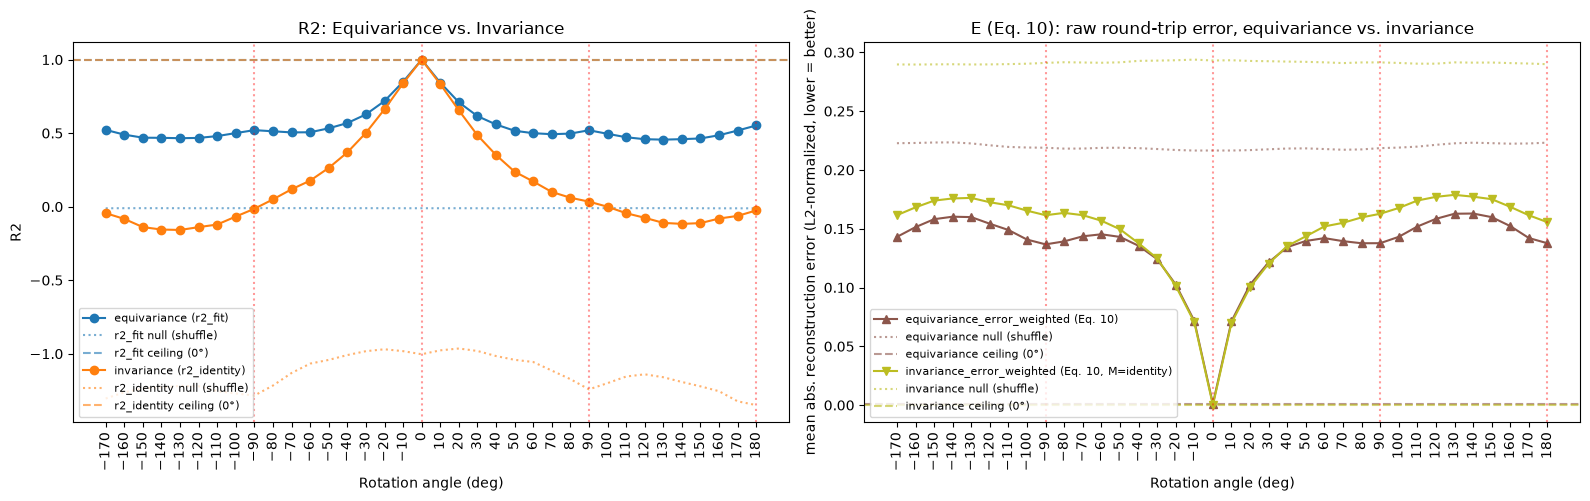

In [51]:
cardinal_angles = [-90, 0, 90, 180]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

r2_identity_ceiling = results_df.loc[results_df["angle"] == 0, "r2_identity"].iloc[0]

ax1.plot(results_df["angle"], results_df["r2_fit"], marker="o", color="tab:blue", label="equivariance (r2_fit)")
ax1.plot(
    results_df["angle"], results_df["r2_null_mean"],
    linestyle=":", color="tab:blue", alpha=0.6, label="r2_fit null (shuffle)",
)
ax1.axhline(R2_CEILING, color="tab:blue", linestyle="--", alpha=0.6, label="r2_fit ceiling (0°)")

ax1.plot(results_df["angle"], results_df["r2_identity"], marker="o", color="tab:orange", label="invariance (r2_identity)")
ax1.plot(
    results_df["angle"], results_df["r2_identity_null_mean"],
    linestyle=":", color="tab:orange", alpha=0.6, label="r2_identity null (shuffle)",
)
ax1.axhline(r2_identity_ceiling, color="tab:orange", linestyle="--", alpha=0.6, label="r2_identity ceiling (0°)")

for ca in cardinal_angles:
    ax1.axvline(ca, color="red", linestyle=":", alpha=0.4)
ax1.set_xlabel("Rotation angle (deg)")
ax1.set_ylabel("R2")
ax1.set_xticks(angles)
ax1.tick_params(axis="x", rotation=90)
ax1.legend(fontsize=8)
ax1.set_title("R2: Equivariance vs. Invariance")

equivariance_ceiling = results_df.loc[results_df["angle"] == 0, "equivariance_error_weighted"].iloc[0]
invariance_ceiling = results_df.loc[results_df["angle"] == 0, "invariance_error_weighted"].iloc[0]

ax2.plot(
    results_df["angle"], results_df["equivariance_error_weighted"],
    marker="^", color="tab:brown", label="equivariance_error_weighted (Eq. 10)",
)
ax2.plot(
    results_df["angle"], results_df["equivariance_error_weighted_null_mean"],
    linestyle=":", color="tab:brown", alpha=0.6, label="equivariance null (shuffle)",
)
ax2.axhline(equivariance_ceiling, color="tab:brown", linestyle="--", alpha=0.6, label="equivariance ceiling (0°)")

ax2.plot(
    results_df["angle"], results_df["invariance_error_weighted"],
    marker="v", color="tab:olive", label="invariance_error_weighted (Eq. 10, M=identity)",
)
ax2.plot(
    results_df["angle"], results_df["invariance_error_weighted_null_mean"],
    linestyle=":", color="tab:olive", alpha=0.6, label="invariance null (shuffle)",
)
ax2.axhline(invariance_ceiling, color="tab:olive", linestyle="--", alpha=0.6, label="invariance ceiling (0°)")

for ca in cardinal_angles:
    ax2.axvline(ca, color="red", linestyle=":", alpha=0.4)
ax2.set_xlabel("Rotation angle (deg)")
ax2.set_ylabel("mean abs. reconstruction error (L2-normalized, lower = better)")
ax2.set_xticks(angles)
ax2.tick_params(axis="x", rotation=90)
ax2.legend(fontsize=8)
ax2.set_title("E (Eq. 10): raw round-trip error, equivariance vs. invariance")

plt.tight_layout()
plt.show()

### Interpretation

Three qualitatively different outcomes are possible:

- **`r2_identity` is high** (close to `r2_fit`): the features are already largely rotation-**invariant** — no linear compensation is needed to predict the rotated features from the unrotated ones.
- **`r2_identity` is low but `r2_fit` is high** (well above `significance_threshold`): the features are not invariant, but rotation can be linearly undone in feature space — this is non-trivial **equivariance** in the sense of Lenc & Vedaldi.
- **Both `r2_identity` and `r2_fit` are close to `r2_null`**: neither the raw features nor any linear map recover the rotated representation — the information needed to relate the two views has effectively been **destroyed** by the network up to this layer.

`R2_CEILING` gives these numbers a scale: `r2_fit` close to `R2_CEILING` means the observed equivariance is as complete as the available data and regularization allow, while a large gap indicates genuine, rotation-induced information loss rather than an estimation-procedure limitation.

`equivariance_score_weighted` and `invariance_score_weighted` are both calibrated like `r2_fit`: `0` at chance level, `→1` for perfect equivariance/invariance. **They are not comparable to each other**, though: `equivariance_error_weighted_null_mean` comes from a Ridge model fit on permutation-broken correspondence, which still shrinks toward the training targets' mean via the fitted intercept - giving it a systematically smaller null than `invariance_error_weighted_null_mean`, which has no fitting step to exploit (raw L1 distance between independent unit vectors). Dividing by a smaller vs. larger null inflates one score relative to the other regardless of which is actually more accurate. Both scores stay internally valid, but Section 6's E panel plots the **raw errors** instead of the scores, since those are computed in the same L2-normalized space and are directly comparable without invoking either null.

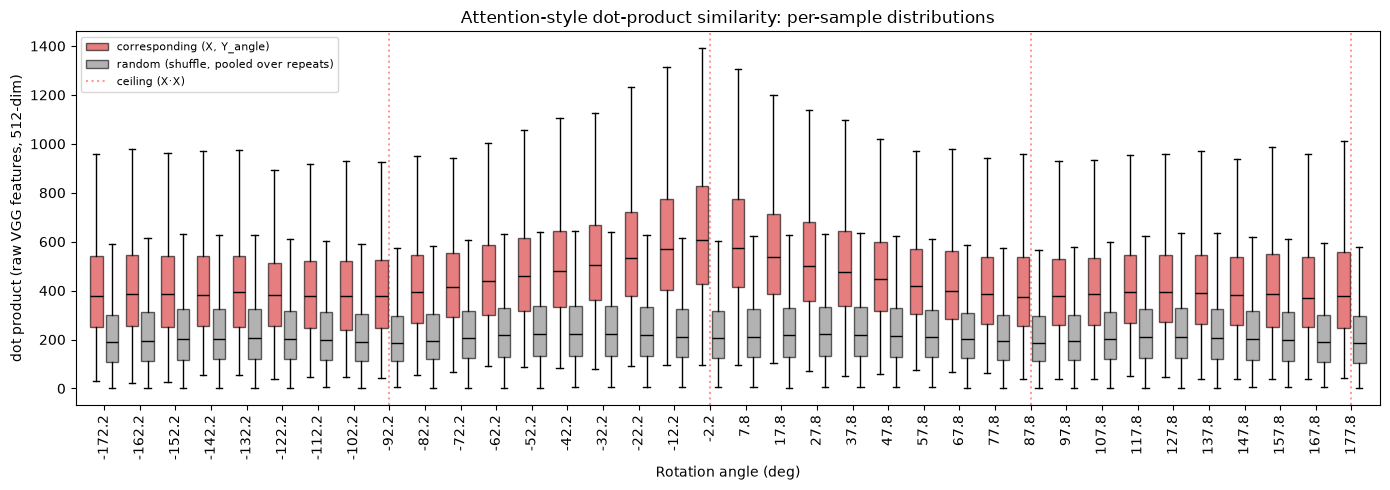

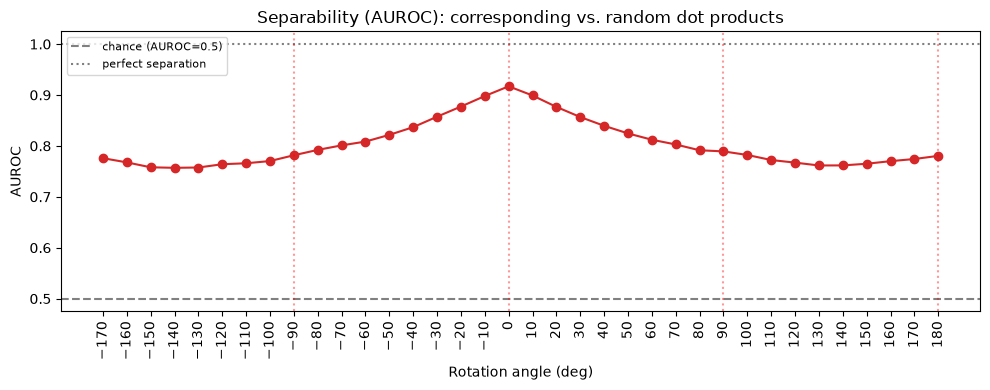

In [ ]:
box_width = 3.5
box_offset = 2.2
corresponding_data = [dot_raw_distributions[a]["corresponding"] for a in angles]
random_data = [dot_raw_distributions[a]["random"] for a in angles]

fig2, ax3 = plt.subplots(figsize=(14, 5))
bp_corr = ax3.boxplot(
    corresponding_data, positions=[a - box_offset for a in angles], widths=box_width,
    patch_artist=True, showfliers=False,
    boxprops=dict(facecolor="tab:red", alpha=0.6), medianprops=dict(color="black"),
)
bp_rand = ax3.boxplot(
    random_data, positions=[a + box_offset for a in angles], widths=box_width,
    patch_artist=True, showfliers=False,
    boxprops=dict(facecolor="gray", alpha=0.6), medianprops=dict(color="black"),
)
#ax3.axhline(DOT_CEILING_RAW, color="tab:red", linestyle="--", alpha=0.6, label="ceiling (X·X)")
for ca in cardinal_angles:
    ax3.axvline(ca, color="red", linestyle=":", alpha=0.4)
ax3.set_xlabel("Rotation angle (deg)")
ax3.set_ylabel("dot product (raw VGG features, 512-dim)")
ax3.set_xticks(angles)
ax3.set_xlim(min(angles) - 8, max(angles) + 8)
ax3.tick_params(axis="x", rotation=90)
ax3.legend(
    handles=[bp_corr["boxes"][0], bp_rand["boxes"][0], ax3.lines[-1]],
    labels=["corresponding (X, Y_angle)", "random (shuffle, pooled over repeats)"],
    fontsize=8,
)
ax3.set_title("Attention-style dot-product similarity: per-sample distributions")
plt.tight_layout()
plt.show()

fig3, ax4 = plt.subplots(figsize=(10, 4))
ax4.plot(results_df["angle"], results_df["dot_raw_auroc"], marker="o", color="tab:red")
ax4.axhline(0.5, color="gray", linestyle="--", label="chance (AUROC=0.5)")
ax4.axhline(1.0, color="gray", linestyle=":", label="perfect separation")
for ca in cardinal_angles:
    ax4.axvline(ca, color="red", linestyle=":", alpha=0.4)
ax4.set_xlabel("Rotation angle (deg)")
ax4.set_ylabel("AUROC")
ax4.set_xticks(angles)
ax4.tick_params(axis="x", rotation=90)
ax4.legend(fontsize=8)
ax4.set_title("Separability (AUROC): corresponding vs. random dot products")
plt.tight_layout()
plt.show()

The dot product mirrors the unnormalized similarity the actual attention mechanism uses (`models.py:position_scores`) - elementwise multiply, sum over channels - on the raw 512-dim VGG features. `corresponding` is each test image's unrotated vs. rotated feature vector; `random` pools all `NULL_REPEATS=10` permutations x 960 test images (9600 values) per angle, shown as a boxplot so individual overlaps between the two groups are visible, not just their means. `ceiling (X·X)` is the mean self dot product of the unrotated set - the value `corresponding` touches exactly at 0°, not a strict upper bound.

The AUROC figure quantifies the boxplot overlap precisely: probability that a random corresponding-pair value exceeds a random random-pair value (0.5 = chance, 1.0 = perfectly separated).

## 7. Invariant Feature Channels (Lenc & Vedaldi, "Quantifying Invariance")

Beyond equivariance (rotation can be undone by a linear map `Mg`), some PCA channels are already close to rotation-**invariant**: their row in `Mg` is dominated by its own diagonal entry, i.e. the channel mostly predicts itself. Per channel `i`, the invariance score is `||Mg[i,:]|| / ||Mg[i,:] with Mg[i,i] set to 0||` (high = diagonal-dominated = invariant; `inf` if the off-diagonal part is exactly zero).

We rank channels by this score and, starting from the most invariant, replace their row with a diagonal-only version (`Mg_bar[i,:] = Mg[i,i] * e_i`, all cross-talk to other channels dropped). The largest number of replaced channels `p` that keeps classification accuracy within 5% (relative) of the full `Mg`'s accuracy is reported as the invariant channel count for that angle.

`Mg` here is `ridge_l2` (PCA space, L2-normalized, `ALPHA_L2`) from the angle sweep. Since `ridge_l2` only predicts a normalized *direction*, compensated predictions are rescaled by the input's own PCA-space norm before `pca.inverse_transform` back to the 512-dim space that the classifier head expects - rotation leaves feature norms roughly unchanged, so this is a reasonable approximation, not an exact inverse.

In [9]:
category_names = sorted(set(Path(p).parent.name for p in file_list))
category_to_idx = {name: i for i, name in enumerate(category_names)}
labels = np.array([category_to_idx[Path(p).parent.name] for p in file_list])
N_CLASSES = len(category_names)

phi2 = nn.Linear(X0.shape[1], N_CLASSES).to(device)
optimizer = torch.optim.Adam(phi2.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

X0_train_t = torch.from_numpy(X0_train).float().to(device)
y_train_t = torch.from_numpy(labels[train_idx]).long().to(device)
X0_test_t = torch.from_numpy(X0_test).float().to(device)
y_test_t = torch.from_numpy(labels[test_idx]).long().to(device)

PHI2_EPOCHS = 50
for epoch in range(PHI2_EPOCHS):
    optimizer.zero_grad()
    loss = criterion(phi2(X0_train_t), y_train_t)
    loss.backward()
    optimizer.step()

phi2.eval()
for p in phi2.parameters():
    p.requires_grad = False

with torch.no_grad():
    phi2_test_acc = (phi2(X0_test_t).argmax(dim=1) == y_test_t).float().mean().item()
print(f"N_CLASSES: {N_CLASSES}, phi2 test accuracy (0deg, chance={1 / N_CLASSES:.3f}): {phi2_test_acc:.3f}")

N_CLASSES: 16, phi2 test accuracy (0deg, chance=0.062): 0.438


In [10]:
def invariance_scores_pca(Mg: np.ndarray) -> np.ndarray:
    """Per-row ratio ||Mg[i,:]|| / ||Mg[i,:] with diagonal suppressed|| - high = diagonal-dominated = invariant."""
    off_diag = Mg.copy()
    np.fill_diagonal(off_diag, 0.0)
    full_norm = np.linalg.norm(Mg, axis=1)
    off_diag_norm = np.linalg.norm(off_diag, axis=1)
    with np.errstate(divide="ignore"):
        return np.where(off_diag_norm == 0.0, np.inf, full_norm / off_diag_norm)


def diagonal_only_rows_pca(Mg: np.ndarray, channel_idx: np.ndarray) -> np.ndarray:
    """Mg with the given rows replaced by their pure diagonal component (cross-talk zeroed)."""
    Mg_bar = Mg.copy()
    Mg_bar[channel_idx, :] = 0.0
    Mg_bar[channel_idx, channel_idx] = Mg[channel_idx, channel_idx]
    return Mg_bar


def classification_accuracy_pca(Mg_variant: np.ndarray, angle: int) -> float:
    """Accuracy of phi_2 on angle-rotated test images, compensated through Mg_variant (PCA space)."""
    ridge_l2 = ridge_l2_by_angle[angle]
    X_angle_r = pca.transform(extract_features(angle)[test_idx])
    X_angle_r_n = l2_normalize(X_angle_r)

    pred_dir = X_angle_r_n @ Mg_variant.T + ridge_l2.intercept_
    pred_dir_n = l2_normalize(pred_dir)
    input_norm = np.linalg.norm(X_angle_r, axis=1, keepdims=True)
    pred_r = pred_dir_n * input_norm  # rescale unit direction by the input's own PCA-space norm

    pred_raw = pca.inverse_transform(pred_r)
    pred_raw_t = torch.from_numpy(pred_raw).float().to(device)
    with torch.no_grad():
        preds = phi2(pred_raw_t).argmax(dim=1)
    return (preds == y_test_t).float().mean().item()


def largest_accepted_p_pca(acc_full: float, Mg: np.ndarray, ranked_idx: np.ndarray, angle: int) -> int:
    """Largest p in [0, N_COMPONENTS] with accuracy >= 95% of acc_full, via binary search.
    Assumes accuracy is roughly non-increasing in p (more channels forced to diagonal-only)."""
    def accepted(p: int) -> bool:
        if p == 0:
            return True
        Mg_bar = diagonal_only_rows_pca(Mg, ranked_idx[:p])
        return classification_accuracy_pca(Mg_bar, angle) >= 0.95 * acc_full

    lo, hi = 0, N_COMPONENTS
    while lo < hi:
        mid = (lo + hi + 1) // 2
        if accepted(mid):
            lo = mid
        else:
            hi = mid - 1
    return lo


invariance_rows_pca = []
for angle in tqdm(angles, desc="Invariance analysis (PCA)"):
    Mg = ridge_l2_by_angle[angle].coef_
    scores = invariance_scores_pca(Mg)
    ranked_idx = np.argsort(-scores)

    acc_full = classification_accuracy_pca(Mg, angle)
    p_max = largest_accepted_p_pca(acc_full, Mg, ranked_idx, angle)

    invariance_rows_pca.append({
        "angle": angle,
        "acc_full": acc_full,
        "p_max": p_max,
        "n_components": N_COMPONENTS,
        "frac_invariant": p_max / N_COMPONENTS,
    })

invariance_df_pca = pd.DataFrame(invariance_rows_pca).sort_values("angle").reset_index(drop=True)
invariance_df_pca


Invariance analysis (PCA):   0%|          | 0/36 [00:00<?, ?it/s]


Invariance analysis (PCA):  19%|█▉        | 7/36 [00:00<00:00, 59.19it/s]


Invariance analysis (PCA):  42%|████▏     | 15/36 [00:00<00:00, 66.18it/s]


Invariance analysis (PCA):  61%|██████    | 22/36 [00:00<00:00, 64.74it/s]


Invariance analysis (PCA):  83%|████████▎ | 30/36 [00:00<00:00, 68.33it/s]


Invariance analysis (PCA): 100%|██████████| 36/36 [00:00<00:00, 66.73it/s]

,angle,acc_full,p_max,n_components,frac_invariant
0,-170,0.302083,9,39,0.230769
1,-160,0.275000,30,39,0.769231
2,-150,0.266667,28,39,0.717949
3,-140,0.257292,27,39,0.692308
4,-130,0.272917,25,39,0.641026
5,-120,0.278125,24,39,0.615385
6,-110,0.272917,23,39,0.589744
7,-100,0.270833,25,39,0.641026
8,-90,0.290625,19,39,0.487179
9,-80,0.301042,20,39,0.512821


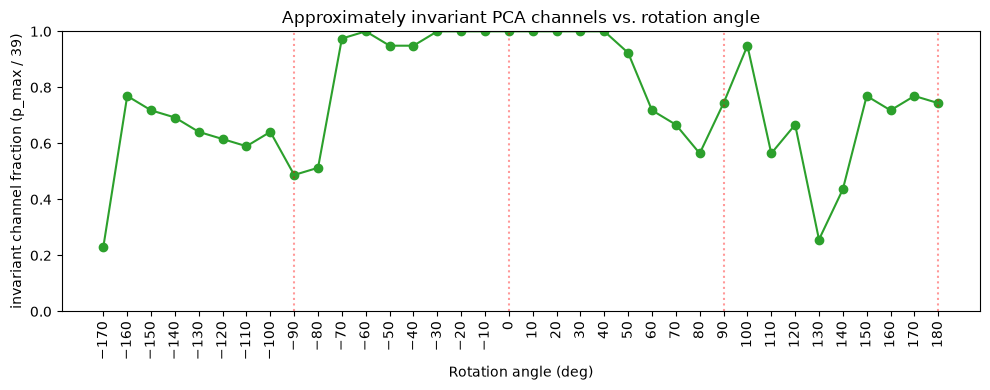

In [11]:
fig5, ax6 = plt.subplots(figsize=(10, 4))
ax6.plot(invariance_df_pca["angle"], invariance_df_pca["frac_invariant"], marker="o", color="tab:green")
for ca in cardinal_angles:
    ax6.axvline(ca, color="red", linestyle=":", alpha=0.4)
ax6.set_xlabel("Rotation angle (deg)")
ax6.set_ylabel(f"invariant channel fraction (p_max / {N_COMPONENTS})")
ax6.set_xticks(angles)
ax6.set_ylim(0, 1)
ax6.tick_params(axis="x", rotation=90)
ax6.set_title("Approximately invariant PCA channels vs. rotation angle")
plt.tight_layout()
plt.show()

A high invariant fraction means many channels can be forced to ignore cross-channel information (diagonal-only) without hurting classification - analogous to the paper's finding of more invariant channels for "expected" transformations (e.g. flips, rescaling) than for unexpected ones (e.g. 90° rotation). `phi_2` here is a linear head trained on this dataset's own categories, not the original ImageNet classifier, so absolute accuracy values aren't comparable to the paper's Table 3 - only the qualitative trend across angles is.

Unlike the row-sparsity/OMP variant below (Section 8), this PCA-space diagonal-ratio score reaches close to `N_COMPONENTS` at `angle=0`: in PCA space, `ridge_l2` fit on the trivial `X0 -> X0` mapping is close to a true identity matrix, so there is little off-diagonal structure to lose when zeroing it out.

## 8. Row-Sparsity Variant (R_k / OMP, Raw 512-dim) - and Its Problem

The paper's row-sparsity regularizer `R_k` (Orthogonal Matching Pursuit, at most `k` nonzero source channels per row) is more faithful to the original method than Section 7's post-hoc diagonal-ratio score, and operates on actual VGG channels instead of PCA components (see the discussion below). Kept here for comparison, but **not used as the main result**, because it turned out to be biased.

The problem: `Ag_dense_by_angle[angle]` is always fit as `Ridge(X0_train_n_raw -> Y_angle_train_n)` - the source side `X0_train_n_raw`, and therefore the Gram matrix that determines how collinear the 512 VGG channels are, is identical at *every* angle. VGG channels are highly collinear (many near-duplicate/dead channels), so Ridge redistributes weight across correlated channels even when fitting the trivial `angle=0` mapping - the diagonal-only replacement then loses real (if redundant) signal for many channels, and `frac_invariant` reaches only ~47% at `angle=0` instead of the expected ~100%. Since this bias comes from the angle-invariant source-side Gram matrix, it affects every angle similarly - so the *shape* of the curve below still carries some signal, but its *absolute* level should not be read as "X% of channels are truly invariant."

In [12]:
# Raw-space equivalent of ALPHA_L2 (Section 5): BEST_ALPHA/ALPHA_L2 were tuned for the 39-dim PCA
# space and would over/under-regularize at 512 dims. Re-select via RidgeCV on the same L2-normalized
# 0deg->90deg pair, now in the raw 512-dim space.
X0_train_n_raw = l2_normalize(X0_train)
Y90_train_n_raw = l2_normalize(Y90[train_idx])
ridge_cv_raw_l2 = RidgeCV(alphas=ALPHA_GRID, fit_intercept=True)
ridge_cv_raw_l2.fit(X0_train_n_raw, Y90_train_n_raw)
ALPHA_RAW_L2 = ridge_cv_raw_l2.alpha_
print(f"Selected alpha for raw 512-dim L2-normalized space (ALPHA_RAW_L2): {ALPHA_RAW_L2}")

Ag_dense_by_angle = {}  # dense reference map per angle, raw 512-dim, L2-normalized - "Ag_dense" in Section 7
for angle in tqdm(angles, desc="Raw-space dense fits"):
    Y_angle_train = X0_train if angle == 0 else extract_features(angle)[train_idx]
    ridge_raw_l2 = Ridge(alpha=ALPHA_RAW_L2, fit_intercept=True)
    ridge_raw_l2.fit(X0_train_n_raw, l2_normalize(Y_angle_train))
    Ag_dense_by_angle[angle] = ridge_raw_l2

Selected alpha for raw 512-dim L2-normalized space (ALPHA_RAW_L2): 1.0



Raw-space dense fits:   0%|          | 0/36 [00:00<?, ?it/s]


Raw-space dense fits:  25%|██▌       | 9/36 [00:00<00:00, 87.78it/s]


Raw-space dense fits:  53%|█████▎    | 19/36 [00:00<00:00, 92.56it/s]


Raw-space dense fits:  81%|████████  | 29/36 [00:00<00:00, 95.33it/s]


Raw-space dense fits: 100%|██████████| 36/36 [00:00<00:00, 93.46it/s]

In [13]:
OMP_K = 3  # fixed number of nonzero source channels per target row (R_k, same k for every channel)


def min_k_scores(X_train_n: np.ndarray, Y_train_n: np.ndarray, X_test_n: np.ndarray, Y_test_n: np.ndarray) -> np.ndarray:
    """Per-target-channel R_k invariance score at a fixed k=OMP_K: channels that select
    themselves as one of their k source channels are ranked by reconstruction quality (R2,
    higher = more invariant -> lower score); channels that don't select themselves score worst."""
    Gram = X_train_n.T @ X_train_n
    Xy = X_train_n.T @ Y_train_n
    with np.errstate(all="ignore"):
        coef = orthogonal_mp_gram(Gram, Xy, n_nonzero_coefs=OMP_K, return_path=False)  # (C, C)

    preds = X_test_n @ coef  # (n_test, C)
    ss_res = np.sum((Y_test_n - preds) ** 2, axis=0)
    ss_tot = np.sum((Y_test_n - Y_test_n.mean(axis=0)) ** 2, axis=0)
    with np.errstate(all="ignore"):
        r2 = 1.0 - ss_res / ss_tot  # NaN for zero-variance targets

    n_channels = X_train_n.shape[1]
    selects_self = coef[np.arange(n_channels), np.arange(n_channels)] != 0.0

    scores = np.full(n_channels, 2.0)  # worst score: didn't select itself (or NaN r2)
    valid = selects_self & ~np.isnan(r2)
    scores[valid] = 1.0 - r2[valid]  # lower = higher R2 = more invariant
    return scores

In [14]:
def diagonal_only_rows(Ag: np.ndarray, channel_idx: np.ndarray) -> np.ndarray:
    """Ag with the given rows replaced by their pure diagonal component (cross-talk zeroed)."""
    Ag_bar = Ag.copy()
    Ag_bar[channel_idx, :] = 0.0
    Ag_bar[channel_idx, channel_idx] = Ag[channel_idx, channel_idx]
    return Ag_bar


def classification_accuracy(Ag_variant: np.ndarray, angle: int) -> float:
    """Accuracy of phi_2 on angle-rotated test images, compensated through Ag_variant (raw 512-dim space)."""
    ridge_raw_l2 = Ag_dense_by_angle[angle]
    X_angle_test = extract_features(angle)[test_idx]
    X_angle_n = l2_normalize(X_angle_test)

    pred_dir = X_angle_n @ Ag_variant.T + ridge_raw_l2.intercept_
    pred_dir_n = l2_normalize(pred_dir)
    input_norm = np.linalg.norm(X_angle_test, axis=1, keepdims=True)
    pred_raw = pred_dir_n * input_norm  # rescale unit direction by the input's own raw-space norm

    pred_raw_t = torch.from_numpy(pred_raw).float().to(device)
    with torch.no_grad():
        preds = phi2(pred_raw_t).argmax(dim=1)
    return (preds == y_test_t).float().mean().item()


def largest_accepted_p(acc_full: float, Ag: np.ndarray, ranked_idx: np.ndarray, angle: int) -> int:
    """Largest p in [0, 512] with accuracy >= 95% of acc_full, via binary search.
    Assumes accuracy is roughly non-increasing in p (more channels forced to diagonal-only)."""
    def accepted(p: int) -> bool:
        if p == 0:
            return True
        Ag_bar = diagonal_only_rows(Ag, ranked_idx[:p])
        return classification_accuracy(Ag_bar, angle) >= 0.95 * acc_full

    lo, hi = 0, Ag.shape[0]
    while lo < hi:
        mid = (lo + hi + 1) // 2
        if accepted(mid):
            lo = mid
        else:
            hi = mid - 1
    return lo


invariance_rows = []
for angle in tqdm(angles, desc="Invariance analysis"):
    Y_angle_train = X0_train if angle == 0 else extract_features(angle)[train_idx]
    Y_angle_test = X0_test if angle == 0 else extract_features(angle)[test_idx]
    scores = min_k_scores(X0_train_n_raw, l2_normalize(Y_angle_train), l2_normalize(X0_test), l2_normalize(Y_angle_test))
    ranked_idx = np.argsort(scores)  # ascending: smallest k (most invariant) first

    Ag = Ag_dense_by_angle[angle].coef_
    acc_full = classification_accuracy(Ag, angle)
    p_max = largest_accepted_p(acc_full, Ag, ranked_idx, angle)
    n_channels = Ag.shape[0]

    invariance_rows.append({
        "angle": angle,
        "acc_full": acc_full,
        "p_max": p_max,
        "n_components": n_channels,
        "frac_invariant": p_max / n_channels,
    })

invariance_df = pd.DataFrame(invariance_rows).sort_values("angle").reset_index(drop=True)
invariance_df


Invariance analysis:   0%|          | 0/36 [00:00<?, ?it/s]

/Users/nadine/Documents/Uni/Hiwi/Codebase/InvariantSearch/.venv/lib/python3.13/site-packages/sklearn/utils/_param_validation.py:218: RuntimeWarning: Orthogonal matching pursuit ended prematurely due to linear dependence in the dictionary. The requested precision might not have been met.
  return func(*args, **kwargs)


/Users/nadine/Documents/Uni/Hiwi/Codebase/InvariantSearch/.venv/lib/python3.13/site-packages/sklearn/utils/_param_validation.py:218: RuntimeWarning: Orthogonal matching pursuit ended prematurely due to linear dependence in the dictionary. The requested precision might not have been met.
  return func(*args, **kwargs)



Invariance analysis:   6%|▌         | 2/36 [00:00<00:02, 12.54it/s]

/Users/nadine/Documents/Uni/Hiwi/Codebase/InvariantSearch/.venv/lib/python3.13/site-packages/sklearn/utils/_param_validation.py:218: RuntimeWarning: Orthogonal matching pursuit ended prematurely due to linear dependence in the dictionary. The requested precision might not have been met.
  return func(*args, **kwargs)


/Users/nadine/Documents/Uni/Hiwi/Codebase/InvariantSearch/.venv/lib/python3.13/site-packages/sklearn/utils/_param_validation.py:218: RuntimeWarning: Orthogonal matching pursuit ended prematurely due to linear dependence in the dictionary. The requested precision might not have been met.
  return func(*args, **kwargs)


... (47 outputs left out)

/Users/nadine/Documents/Uni/Hiwi/Codebase/InvariantSearch/.venv/lib/python3.13/site-packages/sklearn/utils/_param_validation.py:218: RuntimeWarning: Orthogonal matching pursuit ended prematurely due to linear dependence in the dictionary. The requested precision might not have been met.
  return func(*args, **kwargs)



Invariance analysis: 100%|██████████| 36/36 [00:02<00:00, 11.83it/s]


Invariance analysis: 100%|██████████| 36/36 [00:03<00:00, 12.00it/s]

,angle,acc_full,p_max,n_components,frac_invariant
0,-170,0.332292,14,512,0.027344
1,-160,0.306250,18,512,0.035156
2,-150,0.291667,16,512,0.031250
3,-140,0.284375,4,512,0.007812
4,-130,0.280208,16,512,0.031250
5,-120,0.275000,24,512,0.046875
6,-110,0.302083,10,512,0.019531
7,-100,0.286458,43,512,0.083984
8,-90,0.314583,74,512,0.144531
9,-80,0.298958,100,512,0.195312


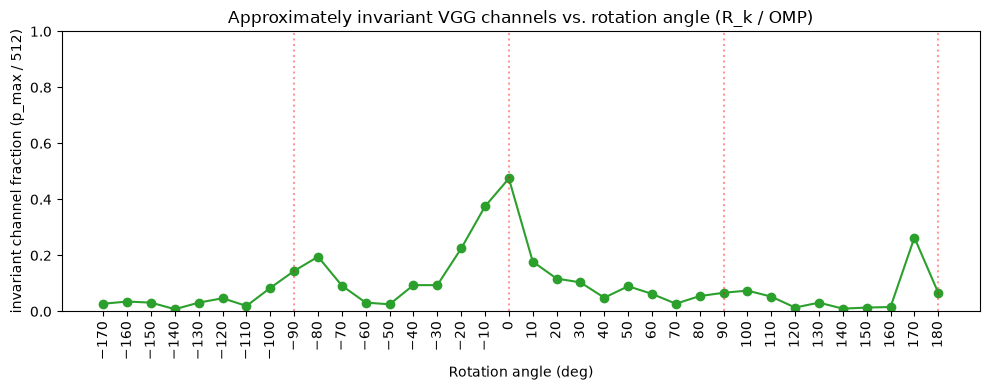

In [15]:
fig4, ax5 = plt.subplots(figsize=(10, 4))
ax5.plot(invariance_df["angle"], invariance_df["frac_invariant"], marker="o", color="tab:green")
for ca in cardinal_angles:
    ax5.axvline(ca, color="red", linestyle=":", alpha=0.4)
ax5.set_xlabel("Rotation angle (deg)")
ax5.set_ylabel("invariant channel fraction (p_max / 512)")
ax5.set_xticks(angles)
ax5.set_ylim(0, 1)
ax5.tick_params(axis="x", rotation=90)
ax5.set_title("Approximately invariant VGG channels vs. rotation angle (R_k / OMP)")
plt.tight_layout()
plt.show()

A high invariant fraction means many VGG channels can be forced to ignore cross-channel information (diagonal-only) without hurting classification - analogous to the paper's finding of more invariant channels for "expected" transformations (e.g. flips, rescaling) than for unexpected ones (e.g. 90° rotation). `phi_2` here is a linear head trained on this dataset's own categories, not the original ImageNet classifier, so absolute accuracy values aren't comparable to the paper's Table 3 - only the qualitative trend across angles is.

## 9. Spatial-Sparsity Regularizer (R_{g,m}) - Not Yet Used

The paper's second regularizer forces each transformed feature value to be predicted only from a local `m x m` neighborhood of the source feature map, exploiting spatial convolution structure - unlike `R_k` (Section 8), which only constrains *how many* source channels are used, not *where* they are. This layer's features are already 1x1x512 at our 32x32 input (no spatial extent left), so `R_{g,m}` has nothing to act on here. It becomes relevant once an earlier layer is examined (e.g. VGG layer 16: 4x4x512). The model and training loop below are defined for that future use - not called against any data in this notebook.

In [16]:
class SpatialEquivarianceModel(nn.Module):
    """Geometric warp (fixed, e.g. rotation by angle_deg) followed by a learned local
    channel-mixing conv (kernel_size x kernel_size) - the R_{g,m} structured-sparsity map."""

    def __init__(self, channels: int, angle_deg: float, kernel_size: int):
        super().__init__()
        self.angle_deg = angle_deg
        self.conv = nn.Conv2d(channels, channels, kernel_size, padding=kernel_size // 2, bias=True)

    def _warp(self, x: torch.Tensor) -> torch.Tensor:
        theta = torch.tensor(-np.deg2rad(self.angle_deg), device=x.device, dtype=x.dtype)
        cos_a, sin_a = torch.cos(theta), torch.sin(theta)
        affine = torch.stack([
            torch.stack([cos_a, -sin_a, torch.zeros_like(theta)]),
            torch.stack([sin_a, cos_a, torch.zeros_like(theta)]),
        ]).unsqueeze(0).expand(x.size(0), -1, -1)
        grid = nn.functional.affine_grid(affine, x.shape, align_corners=False)
        return nn.functional.grid_sample(x, grid, align_corners=False)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.conv(self._warp(x))


def fit_spatial_equivariance_model(
    model: nn.Module, X_train: np.ndarray, Y_train: np.ndarray,
    epochs: int = 100, lr: float = 1e-3, batch_size: int = 64,
) -> list[float]:
    """Adam/MSE training loop for a SpatialEquivarianceModel-like module.
    X_train/Y_train: (N, C, H, W) feature maps (unrotated / rotated-by-angle_deg)."""
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()
    X_t = torch.from_numpy(X_train).float().to(device)
    Y_t = torch.from_numpy(Y_train).float().to(device)
    n = X_t.shape[0]
    losses = []
    for epoch in range(epochs):
        perm = torch.randperm(n)
        epoch_loss = 0.0
        for start in range(0, n, batch_size):
            idx = perm[start:start + batch_size]
            optimizer.zero_grad()
            loss = criterion(model(X_t[idx]), Y_t[idx])
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item() * idx.numel()
        losses.append(epoch_loss / n)
    return losses

## 10. Layerwise Invariance (R_k / OMP, 90°)

Section 8's `R_k`/OMP invariance measure, applied at multiple VGG depths instead of only the final layer, restricted to a single transformation (`angle=90`) to keep the sweep tractable. Following the paper's Eq. (2)-(3)/(5) directly, no PCA or pooling is used: `Ag` operates on the full flattened `(C, H, W)` feature map (`d = C*H*W`), and the diagonal-only compensation is fed back through the *remaining* VGG layers up to layer 30 before reaching the existing, unmodified `phi_2` (`phi2 ∘ (Ag,bg) ∘ φ1(g⁻¹xi)`, Eq. 5) - `phi_2` itself is not retrained per layer.

Since the Gram matrix for OMP is `d×d`, only layers with a practicable flattened dimension are analyzed: `LAYER_INDICES = [9, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30]` (VGG16 `features[0:31]`, 32x32 input) - `d` ranges from 8192 (layers 9/17-22) down to 512 (layer 30); earlier layers (`d` up to 65536) are excluded as infeasible for a dense `d×d` fit. As in Section 8, `Ag` is fit fresh per layer (`X0_l -> Y90_l`, L2-normalized, its own `RidgeCV`-selected alpha), and the same known bias applies at each layer's own `angle=0` reference frame - irrelevant here since only `angle=90` is evaluated, no 0° curve is formed.

In [17]:
LAYER_INDICES = [9, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30]
LAYERWISE_ANGLE = 90

vgg_layers = list(feature_extractor.features.children())


def build_intermediate(l: int) -> nn.Module:
    return nn.Sequential(*vgg_layers[:l + 1]).to(device).eval()


def build_tail(l: int) -> nn.Module:
    return nn.Sequential(*vgg_layers[l + 1:31]).to(device).eval()


def extract_layer_features(l: int, angle: float) -> np.ndarray:
    """Batch-extract (N, C, H, W) feature maps at VGG layer l, rotated by angle."""
    intermediate = build_intermediate(l)
    features = []
    with torch.no_grad():
        for start in tqdm(range(0, len(file_list), BATCH_SIZE), desc=f"layer={l} angle={angle}", leave=False):
            batch_paths = file_list[start:start + BATCH_SIZE]
            batch = torch.stack([load_rotated_rgba_on_gray(Path(p), angle) for p in batch_paths]).to(device)
            feats = intermediate(batch)
            features.append(feats.cpu().numpy())
            del batch, feats
    return np.concatenate(features, axis=0)


In [18]:
layerwise_rows = []
for l in tqdm(LAYER_INDICES, desc="Layerwise invariance"):
    X0_l = extract_layer_features(l, 0)
    Y90_l = extract_layer_features(l, LAYERWISE_ANGLE)
    n_train, n_test = len(train_idx), len(test_idx)
    _, c, h, w = X0_l.shape
    d_l = c * h * w

    X0_l_train = X0_l[train_idx].reshape(n_train, d_l)
    X0_l_test = X0_l[test_idx].reshape(n_test, d_l)
    Y90_l_train = Y90_l[train_idx].reshape(n_train, d_l)
    Y90_l_test = Y90_l[test_idx].reshape(n_test, d_l)

    # Reshape roundtrip must be exact - the compensated prediction is fed back through `tail` below.
    assert np.array_equal(X0_l_test.reshape(n_test, c, h, w), X0_l[test_idx])

    X0_l_train_n = l2_normalize(X0_l_train)
    Y90_l_train_n = l2_normalize(Y90_l_train)
    X0_l_test_n = l2_normalize(X0_l_test)
    Y90_l_test_n = l2_normalize(Y90_l_test)

    ridge_cv_l = RidgeCV(alphas=ALPHA_GRID, fit_intercept=True)
    ridge_cv_l.fit(X0_l_train_n, Y90_l_train_n)

    ridge_l = Ridge(alpha=ridge_cv_l.alpha_, fit_intercept=True)
    ridge_l.fit(X0_l_train_n, Y90_l_train_n)
    Ag_l = ridge_l.coef_

    scores = min_k_scores(X0_l_train_n, Y90_l_train_n, X0_l_test_n, Y90_l_test_n)
    ranked_idx = np.argsort(scores)  # ascending: smallest k-reconstruction error (most invariant) first

    tail = build_tail(l)

    def classification_accuracy_layer(Ag_variant: np.ndarray) -> float:
        pred_dir = X0_l_test_n @ Ag_variant.T + ridge_l.intercept_
        pred_dir_n = l2_normalize(pred_dir)
        input_norm = np.linalg.norm(X0_l_test, axis=1, keepdims=True)
        pred_raw = pred_dir_n * input_norm  # rescale unit direction by the input's own raw-space norm
        pred_map = pred_raw.reshape(n_test, c, h, w)
        pred_map_t = torch.from_numpy(pred_map).float().to(device)
        with torch.no_grad():
            tail_out = tail(pred_map_t)
            logits = phi2(tail_out.view(tail_out.size(0), -1))
            preds = logits.argmax(dim=1)
        return (preds == y_test_t).float().mean().item()

    def largest_accepted_p_layer(acc_full: float) -> int:
        def accepted(p: int) -> bool:
            if p == 0:
                return True
            Ag_bar = diagonal_only_rows(Ag_l, ranked_idx[:p])
            return classification_accuracy_layer(Ag_bar) >= 0.95 * acc_full

        lo, hi = 0, d_l
        while lo < hi:
            mid = (lo + hi + 1) // 2
            if accepted(mid):
                lo = mid
            else:
                hi = mid - 1
        return lo

    acc_full = classification_accuracy_layer(Ag_l)
    p_max = largest_accepted_p_layer(acc_full)

    layerwise_rows.append({
        "layer": l,
        "d": d_l,
        "spatial": f"{c}x{h}x{w}",
        "acc_full": acc_full,
        "p_max": p_max,
        "frac_invariant": p_max / d_l,
    })

layerwise_invariance_df = pd.DataFrame(layerwise_rows).sort_values("layer").reset_index(drop=True)
layerwise_invariance_df


Layerwise invariance:   0%|          | 0/16 [00:00<?, ?it/s]


layer=9 angle=0:   0%|          | 0/75 [00:00<?, ?it/s]


layer=9 angle=0:   1%|▏         | 1/75 [00:00<00:18,  4.03it/s]


layer=9 angle=0:   4%|▍         | 3/75 [00:00<00:07,  9.31it/s]


layer=9 angle=0:   7%|▋         | 5/75 [00:00<00:06, 11.18it/s]


layer=9 angle=0:   9%|▉         | 7/75 [00:00<00:05, 12.14it/s]

... (809 outputs left out)


layer=30 angle=90:  97%|█████████▋| 73/75 [00:02<00:00, 28.38it/s]

/Users/nadine/Documents/Uni/Hiwi/Codebase/InvariantSearch/.venv/lib/python3.13/site-packages/sklearn/utils/_param_validation.py:218: RuntimeWarning: Orthogonal matching pursuit ended prematurely due to linear dependence in the dictionary. The requested precision might not have been met.
  return func(*args, **kwargs)

Layerwise invariance: 100%|██████████| 16/16 [25:59<00:00, 19.64s/it]


Layerwise invariance: 100%|██████████| 16/16 [25:59<00:00, 97.48s/it]

,layer,d,spatial,acc_full,p_max,frac_invariant
0,9,8192,128x8x8,0.263542,500,0.061035
1,16,4096,256x4x4,0.287500,1366,0.333496
2,17,8192,512x4x4,0.300000,576,0.070312
3,18,8192,512x4x4,0.289583,534,0.065186
4,19,8192,512x4x4,0.286458,1774,0.216553
5,20,8192,512x4x4,0.276042,1732,0.211426
6,21,8192,512x4x4,0.286458,1338,0.163330
7,22,8192,512x4x4,0.296875,1976,0.241211
8,23,2048,512x2x2,0.288542,985,0.480957
9,24,2048,512x2x2,0.290625,389,0.189941


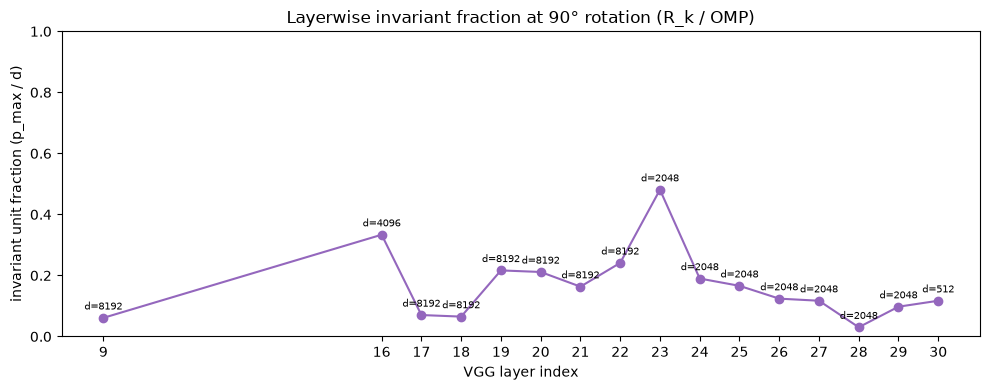

In [19]:
fig6, ax7 = plt.subplots(figsize=(10, 4))
ax7.plot(layerwise_invariance_df["layer"], layerwise_invariance_df["frac_invariant"], marker="o", color="tab:purple")
ax7.set_xlabel("VGG layer index")
ax7.set_ylabel("invariant unit fraction (p_max / d)")
ax7.set_xticks(layerwise_invariance_df["layer"])
ax7.set_ylim(0, 1)
ax7.set_title(f"Layerwise invariant fraction at {LAYERWISE_ANGLE}° rotation (R_k / OMP)")
for _, row in layerwise_invariance_df.iterrows():
    ax7.annotate(
        f"d={row['d']}", (row["layer"], row["frac_invariant"]),
        textcoords="offset points", xytext=(0, 6), fontsize=7, ha="center",
    )
plt.tight_layout()
plt.show()

A rising `frac_invariant` with depth would indicate that later layers increasingly encode rotation-invariant units, consistent with the general expectation that invariance to nuisance transforms builds up over the course of a CNN. As in Section 8, `phi_2` is a linear head trained on this dataset's own categories at layer 30 - here reached via the unmodified `tail` of VGG rather than a fresh classifier, so accuracy differences across layers reflect how much rotation-relevant information a diagonal-only compensation destroys *before* that shared downstream path, not a difference in downstream capacity. The known Section-8 bias (identical source-side Gram matrix inflating apparent invariance loss) applies per layer here too, so cross-layer *trends* are more informative than absolute `frac_invariant` levels.

## 11. Alternative Invariance Metric (Biscione & Bowers, 2021, Appendix D)

A second, independent invariance measure, based on cosine similarity between activations rather than a linear map or reconstruction error. For a layer `l`, reference position `theta_hat` and shifted position `theta`:

- **Cosine similarity**: `C^l(s_i, s_j) = (d^l(s_i) . d^l(s_j)) / (||d^l(s_i)|| ||d^l(s_j)||)`.
- **Translational similarity**: `T(theta) = mean_r C^l(t_theta_hat(o_r), t_theta(o_r))` - same object, reference vs. shifted position.
- **Baseline / uniformity**: `U(theta) = mean_n C^l(t_theta_hat(u_n), t_theta(v_n))` - different objects, reference vs. shifted position. This rules out representational collapse (a layer that maps everything to a similar vector would score high on `T` alone).
- **Invariance metric**: `I(theta) = (T(theta) - U(theta)) / (1 - U(theta))` - baseline-corrected, `1` = perfect invariance, `0` = chance level (indistinguishable from the cross-object baseline).

As a first plausibility check, this is applied only to the existing layer-30 features (`X0`/`extract_features(angle)`, same as Sections 1-6) across the full angle sweep, with `theta_hat = 0`. `T(theta)` and `U(theta)` are computed on the raw 512-dim test-split features (no PCA), mirroring the raw-space dot-product analysis in Sections 5-6. `U(theta)` is estimated the same way as the existing null baselines: `NULL_REPEATS` random permutations of the shifted-side test rows, averaged. Extending this metric across VGG layers at a single fixed transformation is a separate, later step.


In [42]:
def biscione_invariance(ref_acts: np.ndarray, shifted_acts: np.ndarray, n_repeats: int, rng: np.random.Generator) -> dict:
    """Biscione & Bowers (2021), Appendix D: baseline-corrected cosine-similarity invariance.
    ref_acts/shifted_acts: (N, D) activations at theta_hat=0 and theta, same object order (row i
    of both arrays is the same underlying object)."""
    ref_t = torch.from_numpy(ref_acts).float()
    shifted_t = torch.from_numpy(shifted_acts).float()

    T_theta = torch.nn.functional.cosine_similarity(ref_t, shifted_t, dim=1).mean().item()

    u_scores = []
    for _ in range(n_repeats):
        perm = rng.permutation(shifted_acts.shape[0])
        u_scores.append(
            torch.nn.functional.cosine_similarity(ref_t, shifted_t[perm], dim=1).mean().item()
        )
    U_theta = float(np.mean(u_scores))

    I_theta = (T_theta - U_theta) / (1.0 - U_theta)
    return {"T": T_theta, "U": U_theta, "I": I_theta}


In [53]:
biscione_rows = []
for angle in tqdm(angles, desc="Biscione & Bowers invariance"):
    Y_angle_test = X0_test if angle == 0 else extract_features(angle)[test_idx]
    rng = np.random.default_rng(RANDOM_STATE)
    scores = biscione_invariance(X0_test, Y_angle_test, NULL_REPEATS, rng)
    if angle == 0:
        assert np.isclose(scores["T"], 1.0, atol=1e-6), (
            "T(0deg) is not ~1.0 - image correspondence across datasets is broken"
        )
    biscione_rows.append({"angle": angle, **scores})

biscione_df = pd.DataFrame(biscione_rows).sort_values("angle").reset_index(drop=True)
biscione_df


Biscione & Bowers invariance: 100%|██████████| 36/36 [00:00<00:00, 87.99it/s]


,angle,T,U,I
0,-170,0.661932,0.368002,0.465081
1,-160,0.647476,0.371350,0.439236
2,-150,0.632523,0.373570,0.413379
3,-140,0.627794,0.375048,0.404424
4,-130,0.625194,0.375117,0.400198
5,-120,0.629817,0.374756,0.407938
6,-110,0.640110,0.377006,0.422322
7,-100,0.653522,0.378240,0.442747
8,-90,0.668110,0.377361,0.466962
9,-80,0.679184,0.379810,0.482713


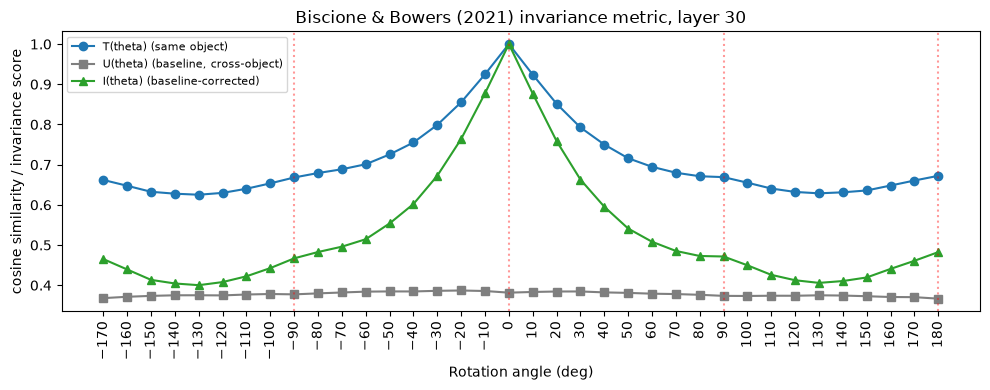

In [54]:
fig7, ax8 = plt.subplots(figsize=(10, 4))
ax8.plot(biscione_df["angle"], biscione_df["T"], marker="o", color="tab:blue", label="T(theta) (same object)")
ax8.plot(biscione_df["angle"], biscione_df["U"], marker="s", color="tab:gray", label="U(theta) (baseline, cross-object)")
ax8.plot(biscione_df["angle"], biscione_df["I"], marker="^", color="tab:green", label="I(theta) (baseline-corrected)")
for ca in cardinal_angles:
    ax8.axvline(ca, color="red", linestyle=":", alpha=0.4)
ax8.set_xlabel("Rotation angle (deg)")
ax8.set_ylabel("cosine similarity / invariance score")
ax8.set_xticks(angles)
ax8.tick_params(axis="x", rotation=90)
ax8.legend(fontsize=8)
ax8.set_title("Biscione & Bowers (2021) invariance metric, layer 30")
plt.tight_layout()
plt.show()


`I(theta)` close to `1` at `theta=0` (by construction, `T(0)=1`) and decreasing as the rotation angle grows away from 0 would be the expected, plausible pattern - mirroring the qualitative shape of `r2_identity` and `dot_raw_auroc` in Sections 5-6, but computed independently via cosine similarity rather than a fitted map or dot product. `U(theta)` staying well below `T(theta)` confirms the layer is not simply collapsing all objects to similar representations. This is the layer-30-only plausibility check; applying `biscione_invariance` across `LAYER_INDICES` at a single fixed transformation is a follow-up step.
